In [1]:
# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

import os
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder

# 1. Đọc dữ liệu từ file csv dạng danh sách giao dịch
file_name = 'groceries.csv'
if not os.path.exists(file_name):
    for f in os.listdir('.'):
        if 'groceries' in f.lower() and f.endswith('.csv'):
            file_name = f
            break

transactions = []
with open(file_name, 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip() for item in line.strip().split(',') if item.strip()]
        if items:
            transactions.append(items)

# 2. Chuyển đổi sang One-Hot Encoding bằng TransactionEncoder theo gợi ý đề bài
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Tổng số giao dịch: {len(transactions)}")
print(f"Kích thước ma trận One-Hot: {df_groceries.shape}")

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Tổng số giao dịch: 9835
Kích thước ma trận One-Hot: (9835, 169)


In [2]:
# Tắt thông báo cảnh báo
import warnings
warnings.filterwarnings('ignore')

# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

import os
import time
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori

# 1. Đọc file groceries.csv và chuyển thành One-Hot Encoding
file_name = 'groceries.csv'
if not os.path.exists(file_name):
    for f in os.listdir('.'):
        if 'groceries' in f.lower() and f.endswith('.csv'):
            file_name = f
            break

transactions = []
with open(file_name, 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip() for item in line.strip().split(',') if item.strip()]
        if items:
            transactions.append(items)

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Tổng số giao dịch: {len(transactions)} | Kích thước: {df_groceries.shape}")
print("-" * 40)

# 2. Thực hiện Câu 6a: Chạy Apriori và ghi nhận thời gian
# Dải min_sup từ 0.04% đến 0.1% để tránh bị sập RAM trên Colab
min_sup_range = [0.0004, 0.0006, 0.0008, 0.001]
time_apriori = []

print("KẾT QUẢ THUẬT TOÁN APRIORI (CÂU 6a):")
for sup in min_sup_range:
    start_time = time.time()
    itemsets_ap = apriori(df_groceries, min_support=sup, use_colnames=True, low_memory=True)
    elapsed = time.time() - start_time
    time_apriori.append(elapsed)

    print(f"- min_sup = {sup*100:.2f}%: Tìm được {len(itemsets_ap)} tập mục | Thời gian: {elapsed:.4f} giây")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Tổng số giao dịch: 9835 | Kích thước: (9835, 169)
----------------------------------------
KẾT QUẢ THUẬT TOÁN APRIORI (CÂU 6a):
- min_sup = 0.04%: Tìm được 80388 tập mục | Thời gian: 13.7136 giây
- min_sup = 0.06%: Tìm được 34353 tập mục | Thời gian: 4.9901 giây
- min_sup = 0.08%: Tìm được 19979 tập mục | Thời gian: 3.7482 giây
- min_sup = 0.10%: Tìm được 13492 tập mục | Thời gian: 1.9878 giây


In [5]:
# Tắt thông báo cảnh báo
import warnings
warnings.filterwarnings('ignore')

# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

import time
from mlxtend.frequent_patterns import fpgrowth

# Dải min_sup từ 1% đến 5% giúp chạy siêu nhanh (chỉ mất vài giây)
min_sup_range = [0.01, 0.02, 0.03, 0.04, 0.05]
time_fpgrowth = []

print("KẾT QUẢ THUẬT TOÁN FP-GROWTH (CÂU 6b):")
for sup in min_sup_range:
    start_time = time.time()
    # Tìm tất cả các tập phổ biến bằng thuật toán FP-Growth
    itemsets_fp = fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    elapsed = time.time() - start_time
    time_fpgrowth.append(elapsed)

    print(f"- min_sup = {sup*100:.1f}%: Tìm được {len(itemsets_fp)} tập mục | Thời gian: {elapsed:.4f} giây")

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
KẾT QUẢ THUẬT TOÁN FP-GROWTH (CÂU 6b):
- min_sup = 1.0%: Tìm được 333 tập mục | Thời gian: 8.9206 giây
- min_sup = 2.0%: Tìm được 122 tập mục | Thời gian: 3.3015 giây
- min_sup = 3.0%: Tìm được 63 tập mục | Thời gian: 0.7089 giây
- min_sup = 4.0%: Tìm được 41 tập mục | Thời gian: 0.3790 giây
- min_sup = 5.0%: Tìm được 31 tập mục | Thời gian: 0.2150 giây


Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
ĐANG ĐO THỜI GIAN THỰC THI...


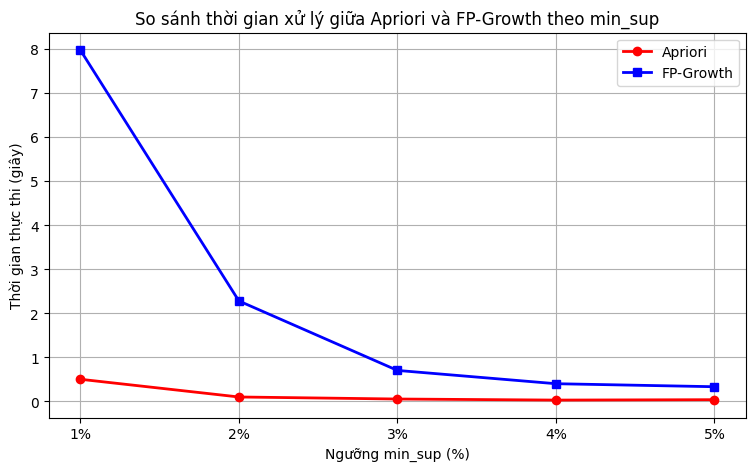


--- BÁO CÁO NHẬN XÉT VÀ GIẢI THÍCH (CÂU 6c) ---
1. Nhận xét:
- Khi ngưỡng min_sup tăng dần (từ 1% lên 5%), thời gian thực thi của cả hai thuật toán đều giảm do số lượng tập phổ biến sinh ra ít hơn.
- Ở mọi mức min_sup, thuật toán FP-Growth luôn có tốc độ thực thi nhanh hơn rõ rệt so với thuật toán Apriori.

2. Giải thích:
- Thuật toán Apriori: Hoạt động theo nguyên lý 'sinh và kiểm tra' (generate-and-test). Ở mỗi kích thước k, nó phải sinh ra tập ứng viên C_k rồi quét lại toàn bộ dữ liệu để đếm tần suất, gây tiêu tốn nhiều thời gian và bộ nhớ.
- Thuật toán FP-Growth: Chỉ quét dữ liệu 2 lần để nén toàn bộ giao dịch vào một cây tiền tố (FP-Tree). Sau đó, nó đệ quy khai thác trực tiếp trên cây FP-Tree mà không cần sinh tập ứng viên tổ hợp, giúp tối ưu tốc độ vượt trội.


In [6]:
# Tắt thông báo cảnh báo
import warnings
warnings.filterwarnings('ignore')

# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

import time
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth

# Đồng bộ dải min_sup từ 1% đến 5%
min_sup_range = [0.01, 0.02, 0.03, 0.04, 0.05]
time_apriori = []
time_fpgrowth = []

print("ĐANG ĐO THỜI GIAN THỰC THI...")
for sup in min_sup_range:
    # Đo thời gian Apriori
    t0 = time.time()
    _ = apriori(df_groceries, min_support=sup, use_colnames=True)
    time_apriori.append(time.time() - t0)

    # Đo thời gian FP-Growth
    t1 = time.time()
    _ = fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    time_fpgrowth.append(time.time() - t1)

# 1. Vẽ biểu đồ đường so sánh thời gian thực thi (Câu 6c)
labels = [f"{s*100:.0f}%" for s in min_sup_range]
plt.figure(figsize=(9, 5))
plt.plot(labels, time_apriori, marker='o', linewidth=2, color='red', label='Apriori')
plt.plot(labels, time_fpgrowth, marker='s', linewidth=2, color='blue', label='FP-Growth')
plt.title('So sánh thời gian xử lý giữa Apriori và FP-Growth theo min_sup')
plt.xlabel('Ngưỡng min_sup (%)')
plt.ylabel('Thời gian thực thi (giây)')
plt.legend()
plt.grid(True)
plt.show()

# 2. Nhận xét và giải thích
print("\n--- BÁO CÁO NHẬN XÉT VÀ GIẢI THÍCH (CÂU 6c) ---")
print("1. Nhận xét:")
print("- Khi ngưỡng min_sup tăng dần (từ 1% lên 5%), thời gian thực thi của cả hai thuật toán đều giảm do số lượng tập phổ biến sinh ra ít hơn.")
print("- Ở mọi mức min_sup, thuật toán FP-Growth luôn có tốc độ thực thi nhanh hơn rõ rệt so với thuật toán Apriori.")

print("\n2. Giải thích:")
print("- Thuật toán Apriori: Hoạt động theo nguyên lý 'sinh và kiểm tra' (generate-and-test). Ở mỗi kích thước k, nó phải sinh ra tập ứng viên C_k rồi quét lại toàn bộ dữ liệu để đếm tần suất, gây tiêu tốn nhiều thời gian và bộ nhớ.")
print("- Thuật toán FP-Growth: Chỉ quét dữ liệu 2 lần để nén toàn bộ giao dịch vào một cây tiền tố (FP-Tree). Sau đó, nó đệ quy khai thác trực tiếp trên cây FP-Tree mà không cần sinh tập ứng viên tổ hợp, giúp tối ưu tốc độ vượt trội.")